In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("powerplant_data.csv")

In [3]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [4]:
X = df.drop("PE",axis = 1)
y = df["PE"]

In [6]:
y.head()

0    480.48
1    445.75
2    438.76
3    453.09
4    464.43
Name: PE, dtype: float64

In [7]:
# Split out data

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split( 
    X, y , test_size = 0.2, random_state = 42
)

In [9]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [10]:
X_test_scaled

array([[ 1.34499288,  0.23869298, -1.28658067, -1.10532538],
       [ 0.81095912,  1.36269098, -0.74140656,  0.26485915],
       [-0.2437241 , -0.73900436,  1.99970178, -0.19713193],
       ...,
       [-0.67068342, -1.15902881, -0.29951077, -0.10651852],
       [ 1.31420898,  1.33752097, -0.87346737, -0.44288647],
       [-0.2611237 , -0.27021304,  0.37433797,  1.10646548]])

In [11]:
import torch 
import torch.nn as nn

X_train_tensor = torch.tensor(X_train_scaled, dtype = torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype = torch.float32).view(-1,1)

X_test_tensor = torch.tensor(X_test_scaled, dtype = torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype = torch.float32).view(-1,1)



In [12]:
print(type(X_train_scaled), type(y_train))

<class 'numpy.ndarray'> <class 'pandas.core.series.Series'>


In [15]:
X_train.shape

(7654, 4)

In [13]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)


In [14]:
train_loader = DataLoader(train_dataset , batch_size = 32, shuffle = True)
test_loader = DataLoader(test_dataset, batch_size = 32)

In [16]:
class ANN(nn.Module):
    def __init__(self):
        super(ANN,self).__init__()

        self.model = nn.Sequential(

            nn.Linear(X_train.shape[1],6),
            nn.ReLU(),

            nn.Linear(6,6),
            nn.ReLU(),

            nn.Linear(6,1)
        )

    def forward(self, x):
        return self.model(x)

In [17]:
import torch.optim as optim

model = ANN()

# loss, optimizer

crietrion = nn.MSELoss()
optimizer = optim.Adam(model.parameters())

In [18]:
# Train the ANN

train_losses = []
val_losses = []

best_val_loss = float("inf")


epochs = 100

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for xb,yb in train_loader:

        optimizer.zero_grad()
        outputs = model(xb)
        loss = crietrion(outputs,yb)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_train_loss = running_loss /len(train_loader)
    train_losses.append(epoch_train_loss)



    #Validation
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for xb,yb in test_loader:
            outputs = model(xb)
            loss = crietrion(outputs, yb)

            running_val_loss += loss

    epoch_val_loss = running_val_loss /len(test_loader)
    val_losses.append(epoch_val_loss)


    print(f"epoch {epoch+1}/{epochs} ==> train loss = {epoch_train_loss} & val loss = {epoch_val_loss}")


    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), "best_model.pt")
        


epoch 1/100 ==> train loss = 205829.74134114583 & val loss = 204311.046875
epoch 2/100 ==> train loss = 198205.6736328125 & val loss = 185830.953125
epoch 3/100 ==> train loss = 158432.09280598958 & val loss = 124789.53125
epoch 4/100 ==> train loss = 88268.52786458333 & val loss = 55918.296875
epoch 5/100 ==> train loss = 36878.76955566406 & val loss = 24753.419921875
epoch 6/100 ==> train loss = 20574.57567952474 & val loss = 17484.86328125
epoch 7/100 ==> train loss = 15843.902478027343 & val loss = 13736.6552734375
epoch 8/100 ==> train loss = 12259.218082682291 & val loss = 10272.333984375
epoch 9/100 ==> train loss = 8867.449330647787 & val loss = 7093.76708984375
epoch 10/100 ==> train loss = 5954.116115315755 & val loss = 4537.00830078125
epoch 11/100 ==> train loss = 3740.1250178019204 & val loss = 2780.71533203125
epoch 12/100 ==> train loss = 2307.624934132894 & val loss = 1768.2110595703125
epoch 13/100 ==> train loss = 1478.294348780314 & val loss = 1180.7335205078125
epoc

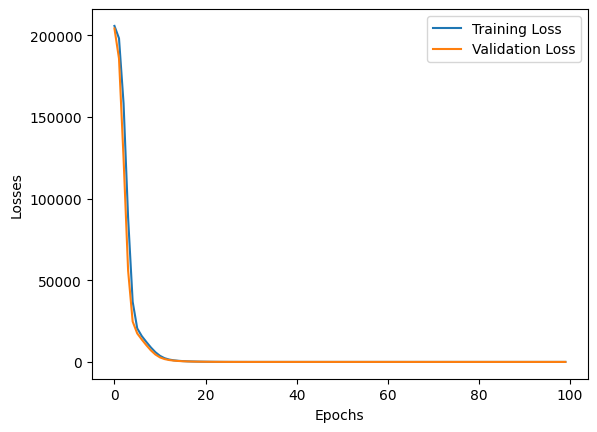

In [19]:
import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
    "Training Loss" : train_losses,
    "Validation Loss": val_losses
})

plt.plot(loss_df["Training Loss"], label = "Training Loss")
plt.plot(loss_df["Validation Loss"], label = "Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()


In [20]:
# Loading the best model

model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [21]:
# Evaluation 

model.eval()

with torch.no_grad():
    train_preds = model(X_train_tensor)
    test_preds = model(X_test_tensor)

    train_mse_loss = crietrion(train_preds, y_train_tensor)
    test_mse_loss = crietrion(test_preds, y_test_tensor)


print("Training MSE:", train_mse_loss.item())

print("Testing MSE:", test_mse_loss.item())

Training MSE: 20.25044059753418
Testing MSE: 18.51585578918457


In [22]:
from sklearn.metrics import r2_score

print("r^2 score = ", r2_score(y_test, test_preds))

r^2 score =  0.9352918585788961


In [23]:
predicted_df = pd.DataFrame(test_preds.numpy(), columns = ["Predicted Values"])
actual_df = pd.DataFrame(y_test.values, columns = ["Actual Values"])

pd.concat([predicted_df, actual_df], axis = 1)


,Predicted Values,Actual Values
0,435.073456,433.27
1,436.501984,438.16
2,461.162689,458.42
3,476.125732,480.82
4,435.096405,441.41
...,...,...
1909,451.082336,456.70
1910,431.278473,438.04
1911,467.606598,467.80
1912,430.680237,437.14
